In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
marks=np.array([10,20,30,40])
print("marks",marks)
print("average",np.mean(marks))
print("maximum",np.max(marks))
print("minimum",np.min(marks))

marks [10 20 30 40]
average 25.0
maximum 40
minimum 10


In [4]:
import pandas as pd
df=pd.read_csv(r"C:\Users\User\Desktop\me journey\aml_lab_preparation\data\student-data.csv")
print(df.head())
print(df.shape)
print("next")
print(df.isnull().sum())


  school sex  age address famsize  ... Dalc  Walc  health absences passed
0     GP   F   18       U     GT3  ...    1     1       3        6     no
1     GP   F   17       U     GT3  ...    1     1       3        4     no
2     GP   F   15       U     LE3  ...    2     3       3       10    yes
3     GP   F   15       U     GT3  ...    1     1       5        2    yes
4     GP   F   16       U     GT3  ...    1     2       5        4    yes

[5 rows x 31 columns]
(395, 31)
next
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
passed        0
dtype: int64


In [5]:
x=df[["school","sex","age","address","famsize","health","absences"]]
y=df["passed"]

NOW THE L1 LESSON IS DONE NOW COMES THE DATA PREPROCESSING


In [2]:
import pandas as pd
from sklearn.impute import SimpleImputer
df=pd.read_csv(r"C:\Users\User\Desktop\me journey\aml_lab_preparation\data\Data.csv")
imputer=SimpleImputer(strategy="median")
df[["Age","Salary"]]=imputer.fit_transform(
    df[["Age","Salary"]]
)

print(df.isnull().sum())

Country      0
Age          0
Salary       0
Purchased    0
dtype: int64


In [3]:
import pandas as pd
df=pd.DataFrame({
    "city":["udupi","mangalore","udupi"]
})
encoded=pd.get_dummies(df,columns=["city"],dtype=int)
print(encoded)

   city_mangalore  city_udupi
0               0           1
1               1           0
2               0           1


In [ ]:

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_scaled=scaler.fit_transform(X)
print(x_scaled)

NOW LETS WRITE THE WHOLE PREPROCESSING PIPELINE


In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [13]:
df=pd.read_csv(r"C:\Users\User\Desktop\me journey\aml_lab_preparation\data\Data.csv")
x=df.drop(columns=["Purchased"])
y=df["Purchased"]
num_cols=x.select_dtypes(include="number").columns
cat_cols=x.select_dtypes(include="number").columns

#numerical preprossing
num_pipline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

#categorical preprossign
cat_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoded",OneHotEncoder(handle_unknown="ignore"))

])

preprocessor=ColumnTransformer([
    ("num",num_pipline,num_cols),
    ("cat",cat_pipeline,cat_cols)
])

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

x_train_processed=preprocessor.fit_transform(x_train)
x_test_processed=preprocessor.transform(x_test)

print("training shape",x_train_processed.shape)
print("testing shape",x_test_processed.shape)

training shape (8, 16)
testing shape (2, 16)


LETS START DECISION TREE


[[55  9]
 [ 8 28]]
0.83
fold scores [0.85       0.88333333 0.83333333 0.83333333 0.91666667]
mean accuracy 0.8633333333333335


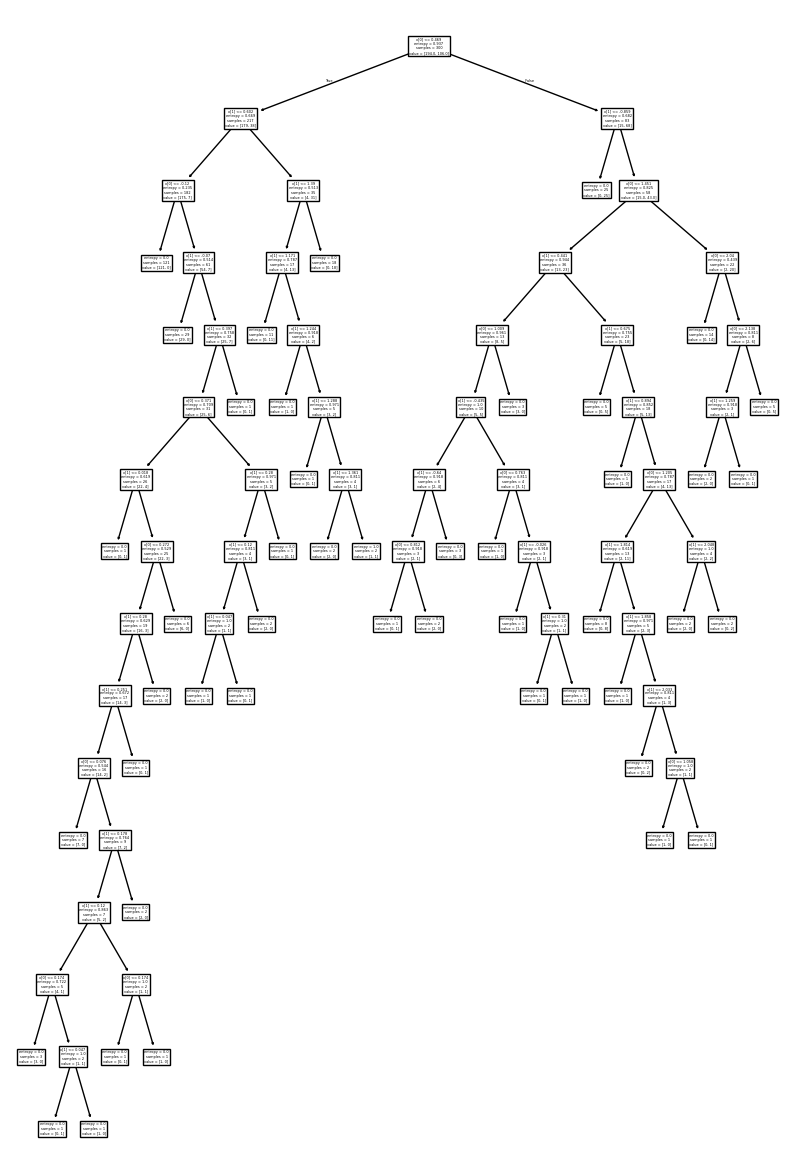

In [18]:
import pandas as pd
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn import  tree
import matplotlib.pyplot as plt

df=pd.read_csv(r"C:\Users\User\Desktop\me journey\aml_lab_preparation\data\Social_Network_Ads - Social_Network_Ads.csv")
x=df.iloc[:,[2,3]].values
y=df.iloc[:,-1].values

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

classifier=DecisionTreeClassifier(
    criterion="entropy",random_state=0
)

classifier.fit(x_train,y_train)
y_pred=classifier.predict(x_test)

cm=confusion_matrix(y_pred,y_test)
print(cm)
accuracy_score=accuracy_score(y_pred,y_test)
print(accuracy_score)
plt.figure(figsize=(10,15))
tree.plot_tree(classifier)

scores=cross_val_score(classifier,x_train,y_train,cv=5)
print("fold scores",scores)
print("mean accuracy",scores.mean())


L4-DECISION TREEE OVERFITTING,PRUING,REGRESSION


In [20]:
from sklearn.tree import  DecisionTreeClassifier
from sklearn.metrics import accuracy_score

classifier=DecisionTreeClassifier(
    criterion="entropy",
    random_state=0,
    max_depth=3,
    min_samples_split=5,
    ccp_alpha=0.01
)
classifier.fit(x_train,y_train)
y_pred=classifier.predict(x_test)
accuracy=accuracy_score(y_pred,y_test)
print(accuracy)

0.92


In [22]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeRegressor
import numpy as np  
df=pd.read_csv(r"C:\Users\User\Desktop\me journey\aml_lab_preparation\data\Salary_Data.csv")
x=df[["YearsExperience"]]
y=df["Salary"]

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

classifier=DecisionTreeRegressor(
    random_state=0
)
classifier.fit(x_train,y_train)
y_pred=classifier.predict(x_test)

mse=root_mean_squared_error(y_pred,y_test)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

print(mse)
print(rmse)
print(r2)


5049.652306512466
71.06090561280841
0.9764754205531827


L5:linear regression ,MSE,RMSE,R2 

In [23]:
import pandas as pd
import numpy as np 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

df=pd.read_csv(r"C:\Users\User\Desktop\me journey\aml_lab_preparation\data\Salary_Data.csv")

x=df[["YearsExperience"]]
y=df["Salary"]

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

print(mse)
print(mae)
print(r2)

12823412.298126549
2446.1723690465055
0.988169515729126


L6:LOGISTIC REGRESSION , RIDGE, LASSO AND CROSS VALIDATION

In [26]:
import pandas as pd
import numpy as np 
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import  StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
df=pd.read_csv(r"C:\Users\User\Desktop\me journey\aml_lab_preparation\data\Social_Network_Ads - Social_Network_Ads.csv")

x=df[["Age","EstimatedSalary"]]
y=df[["Purchased"]]

x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.25,random_state=0
)

sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

model=LogisticRegression(
    random_state=0
)

model.fit(x_train,y_train)

y_pred=model.predict(x_test)

cm=confusion_matrix(y_pred,y_test)
print(cm)
accuracy_score=accuracy_score(y_pred,y_test)
print(accuracy_score)
plt.figure(figsize=(10,15))


scores=cross_val_score(classifier,x_train,y_train,cv=5)
print("fold scores",scores)
print("mean accuracy",scores.mean())

[[65  8]
 [ 3 24]]
0.89
fold scores [0.25925926 0.12457912 0.06698565 0.26128591 0.6031746 ]
mean accuracy 0.2630569085317447


c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


<Figure size 1000x1500 with 0 Axes>

In [31]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score

# 1. Train Ridge Regressor
ridge = Ridge(alpha=1.0)
ridge.fit(x_train, y_train)
y_pred = ridge.predict(x_test)

# 2. Evaluate with regression metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.4f}")
print(f"R2 Score: {r2:.4f}")

# 3. Cross-validation (scoring with R2 or neg_mean_squared_error)
scores = cross_val_score(ridge, x_train, y_train, cv=5, scoring='r2')
print("Fold R2 scores:", scores)
print("Mean R2:", scores.mean())


Mean Squared Error: 0.0987
R2 Score: 0.5464
Fold R2 scores: [0.4238168  0.40875911 0.24582775 0.40852573 0.56081206]
Mean R2: 0.40954828941601396


In [36]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=1.0)
lasso.fit(x_train, y_train)

y_pred = lasso.predict(x_test)

# 2. Evaluate with regression metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.4f}")
print(f"R2 Score: {r2:.4f}")

# 3. Cross-validation (scoring with R2 or neg_mean_squared_error)
scores = cross_val_score(ridge, x_train, y_train, cv=5, scoring='r2')
print("Fold R2 scores:", scores)
print("Mean R2:", scores.mean())


Mean Squared Error: 0.2201
R2 Score: -0.0115
Fold R2 scores: [0.4238168  0.40875911 0.24582775 0.40852573 0.56081206]
Mean R2: 0.40954828941601396


In [42]:
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV

df=load_diabetes()
# print(df)
x=df.data
y=df.target

scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

model=LassoCV(cv=5,random_state=42,max_iter=10000)
model.fit(x_scaled,y)

print(model.alpha_)
print(model.coef_)


0.07891843500595844
[ -0.30892106 -11.22504613  24.81684888  15.27130382 -27.08540992
  14.38623131  -0.           6.83504132  31.86497214   3.17904105]


In [6]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.feature_selection import SelectKBest, f_classif

# 1. Load dataset
df = load_iris()
x = df.data 
y = df.target

# 2. Select top 2 features using ANOVA F-value
selector = SelectKBest(score_func=f_classif, k=2)
x_selected = selector.fit_transform(x, y)

# 3. Print selected features and scores
selected_features = np.array(df.feature_names)[selector.get_support()]
print("Selected features:", selected_features)
print("Feature scores:", selector.scores_)


Selected features: ['petal length (cm)' 'petal width (cm)']
Feature scores: [ 119.26450218   49.16004009 1180.16118225  960.0071468 ]


In [12]:
import pandas as pd
from sklearn.feature_selection import VarianceThreshold
df=pd.read_csv(r"C:\Users\User\Desktop\me journey\aml_lab_preparation\data\data-1.csv")
x=df
selector=VarianceThreshold(threshold=0.2)
x_selected=selector.fit_transform(x)
selcted_col=x.columns[selector.get_support()]
print(list(selcted_col))

['Age', 'items']


In [13]:
correlation_matrix=df.corr(numeric_only=True)
print(correlation_matrix)

                offer      Age  online payment    items
offer             NaN      NaN             NaN      NaN
Age               NaN  1.00000             NaN  0.33076
online payment    NaN      NaN             NaN      NaN
items             NaN  0.33076             NaN  1.00000
